# ScamShield risk model: short analysis

Companion to `docs/model_metrics.md`. Run `uv run python -m ml.train` from `backend/` first; this notebook reads its outputs.

All data is the public, synthetic PaySim dataset.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import precision_recall_curve

# Make the backend packages importable wherever the notebook is started from.
BACKEND = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(BACKEND))
from ml.explain import explain, load_model
from ml.features import FEATURE_LABELS, FEATURES, load_paysim

DATA_DIR = BACKEND.parent / "data"
raw = load_paysim(DATA_DIR)  # leaky columns are never loaded
raw.shape

C:\Users\ADMIN\Documents\Software_Development\AI_Builder_Cup_Hackathon\scamshield\backend\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(6362620, 8)

## 1. Where does fraud occur?

Only in TRANSFER and CASH_OUT, so the model is trained on those two types.

In [2]:
raw.groupby("type")["isFraud"].agg(transactions="size", frauds="sum")

,transactions,frauds
type,,
CASH_IN,1399284,0
CASH_OUT,2237500,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,532909,4097


## 2. How often do senders repeat?

Almost never, so there is no per-customer history to learn from. Payees do repeat.

In [3]:
senders = raw["nameOrig"].value_counts()
payees = raw["nameDest"].value_counts()
pd.DataFrame({
    "unique accounts": [len(senders), len(payees)],
    "accounts seen more than once": [(senders > 1).sum(), (payees > 1).sum()],
    "max transactions per account": [senders.max(), payees.max()],
}, index=["senders (nameOrig)", "payees (nameDest)"])

,unique accounts,accounts seen more than once,max transactions per account
senders (nameOrig),6353307,9298,3
payees (nameDest),2722362,459658,113


## 3. Volume and fraud over time

Volume collapses after step 400 while frauds per hour stay flat, so the fraud rate is much higher in the test period. Dashed lines mark the train / validation / test boundaries.

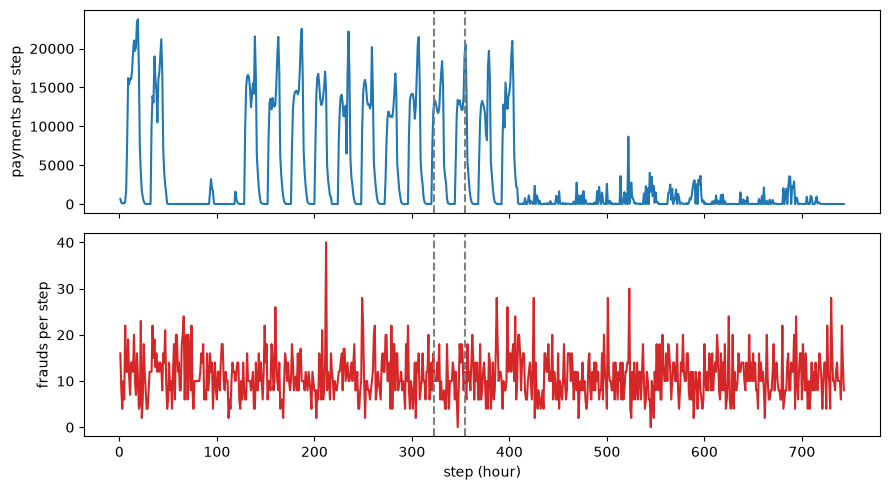

In [4]:
config = json.loads((BACKEND / "ml" / "artifacts" / "feature_config.json").read_text())
scope = raw[raw["type"].isin(config["model_types"])]
per_step = scope.groupby("step")["isFraud"].agg(payments="size", frauds="sum")

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(per_step.index, per_step["payments"]); axes[0].set_ylabel("payments per step")
axes[1].plot(per_step.index, per_step["frauds"], color="tab:red"); axes[1].set_ylabel("frauds per step")
axes[1].set_xlabel("step (hour)")
for ax in axes:
    for boundary in (config["split"]["train_steps"][1], config["split"]["valid_steps"][1]):
        ax.axvline(boundary, color="gray", linestyle="--")
plt.tight_layout()

## 4. Test-set performance

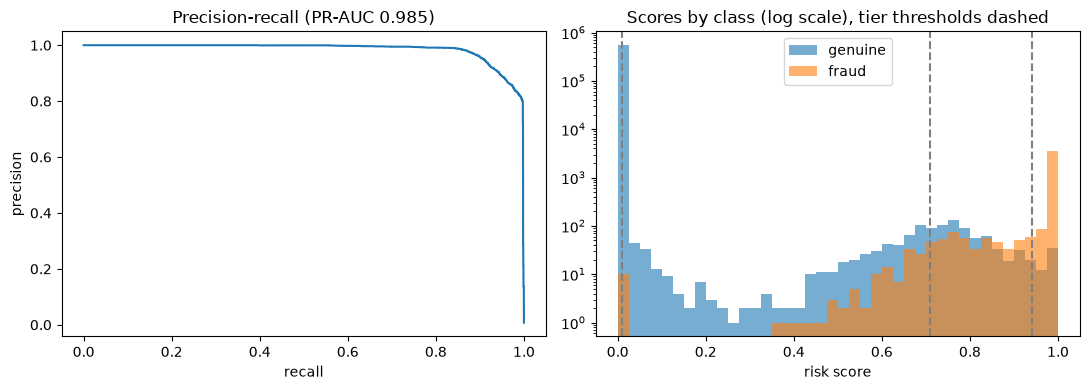

In [5]:
test = pd.read_pickle(DATA_DIR / "test_scored.pkl")
precision, recall, _ = precision_recall_curve(test["isFraud"], test["score"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(recall, precision); axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision")
axes[0].set_title(f"Precision-recall (PR-AUC {config['test_pr_auc']:.3f})")
bins = np.linspace(0, 1, 41)
axes[1].hist(test.loc[test["isFraud"] == 0, "score"], bins=bins, alpha=0.6, label="genuine")
axes[1].hist(test.loc[test["isFraud"] == 1, "score"], bins=bins, alpha=0.6, label="fraud")
for name, value in config["tier_thresholds"].items():
    axes[1].axvline(value, color="gray", linestyle="--")
axes[1].set_yscale("log"); axes[1].set_xlabel("risk score"); axes[1].set_title("Scores by class (log scale), tier thresholds dashed")
axes[1].legend(); plt.tight_layout()

In [6]:
tiers = test.groupby("tier")["isFraud"].agg(payments="size", frauds="sum").reindex(["Low", "Medium", "High", "Critical"])
tiers["fraud rate"] = (tiers["frauds"] / tiers["payments"]).round(3)
tiers

,payments,frauds,fraud rate
tier,,,
Low,546999,10,0.000
Medium,725,128,0.177
High,1070,466,0.436
Critical,3710,3654,0.985


## 5. Why is the model so accurate?

PaySim fraud almost always moves exactly the sender's whole balance. This is a simulator pattern; real fraud is not this clean.

In [7]:
drains = scope["amount"] == scope["oldbalanceOrg"]
drains.groupby(scope["isFraud"].map({0: "genuine", 1: "fraud"})).mean().rename("share moving exactly the whole balance")

isFraud
fraud      0.978205
genuine    0.000000
Name: share moving exactly the whole balance, dtype: float64

## 6. SHAP explanations

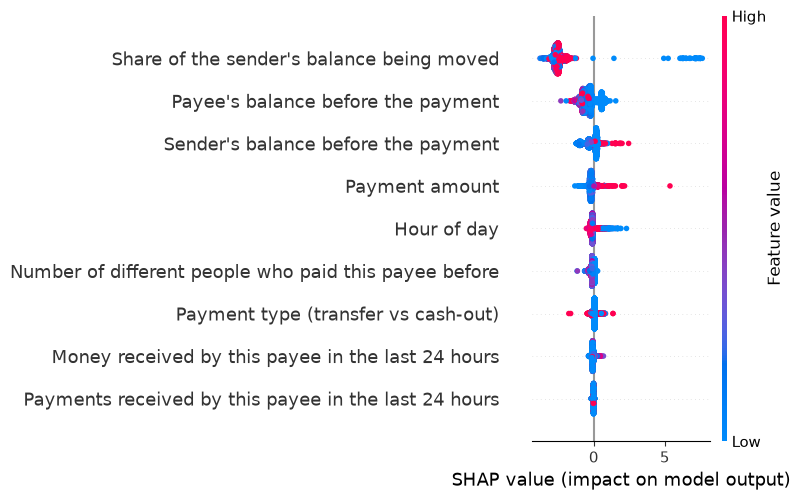

In [8]:
booster, _ = load_model()
sample = test[FEATURES].sample(5000, random_state=42)
shap_values = shap.TreeExplainer(booster).shap_values(sample)
shap.summary_plot(shap_values, sample.rename(columns=FEATURE_LABELS), show=False)
plt.tight_layout()

One flagged payment explained in plain English (what the analyst and Gemini will see):

In [9]:
example = test[test["tier"] == "Critical"].head(1)
print(f"score {example['score'].iloc[0]:.3f}, actual fraud = {bool(example['isFraud'].iloc[0])}")
pd.DataFrame(explain(booster, example[FEATURES])[0])[["text", "direction", "shap_value"]]

score 0.999, actual fraud = True


,text,direction,shap_value
0,The payment moves 100% of the sender's balance.,increases risk,7.1722
1,"The sender's balance before the payment was 5,...",increases risk,1.5734
2,"The payment amount is 5,338,163.",increases risk,1.4804
3,The payee's balance before the payment was 0.,increases risk,0.5839
4,The payment is a transfer to another account.,increases risk,0.4256
